# Chapter 6 - Statistical Machine Learning

## Learning objectives
Statistical machine learning learns predictive rules from labeled examples while balancing fit, generalization, and interpretability. This notebook covers k-nearest neighbors, tree models, bagging/random forests, and boosting with cross-validated comparison.

**Tools:** distance metrics, scaling, one-hot encoding, kNN, decision trees, random forests, feature importance, gradient boosting, and hyperparameter tuning.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Study notes: validation and k-nearest neighbors

For kNN regression, $\hat y(x)=\frac{1}{k}\sum_{i\in N_k(x)}y_i$; for classification, the predicted class is the neighborhood majority vote. Common Euclidean distance is $d(x,z)=\sqrt{\sum_j(x_j-z_j)^2}$. Features on larger scales dominate this distance, so standardization is essential. One-hot encode nominal categories; do not imply numeric order.

The hyperparameter $k$ controls the bias-variance trade-off: small $k$ makes a flexible, noisy boundary; large $k$ smooths away local signal. Select it inside cross-validation, not on the test set.

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
knn = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(knn, {"model__n_neighbors": range(1, 22, 2), "model__weights": ["uniform", "distance"]}, cv=cv, scoring="accuracy")
search.fit(X_train, y_train)
print("Best kNN settings:", search.best_params_)
print(f"Test accuracy: {accuracy_score(y_test, search.predict(X_test)):.3f}")
pd.DataFrame(search.cv_results_)[["param_model__n_neighbors", "param_model__weights", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head()

Best kNN settings: {'model__n_neighbors': 1, 'model__weights': 'uniform'}
Test accuracy: 0.956


,param_model__n_neighbors,param_model__weights,mean_test_score
0,1,uniform,0.977778
1,1,distance,0.977778
2,3,uniform,0.977493
3,3,distance,0.977493
19,19,distance,0.970370


## 2. Decision trees

Trees recursively split predictors into regions. For classification, a common split criterion is Gini impurity,

$$G=1-\sum_{k=1}^{K}\hat p_k^2,$$

and a good split reduces weighted impurity. For regression, a split reduces squared error. Trees capture interactions and nonlinearities without scaling, but unrestricted trees can memorize training noise. Important controls: `max_depth`, `min_samples_leaf`, `min_samples_split`, and cost-complexity pruning `ccp_alpha`.

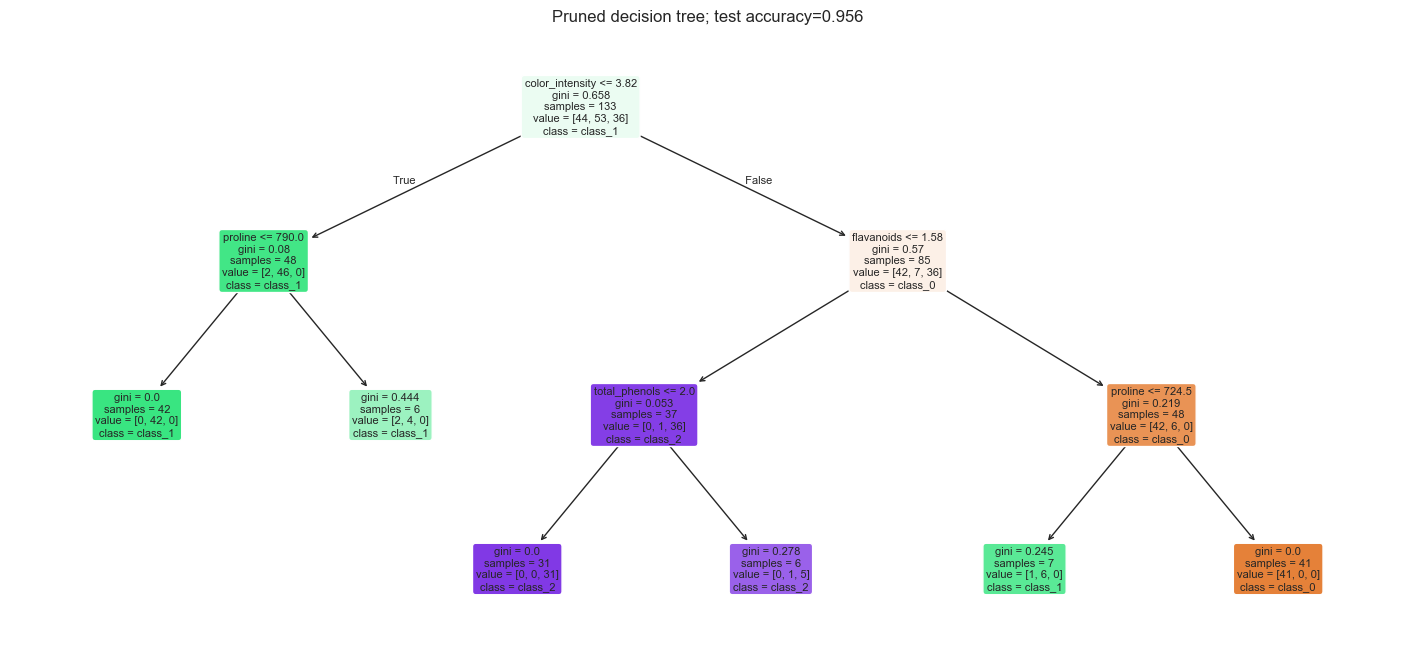

In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# min_samples_leaf prevents a leaf supported by only one or two unstable records.
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=42)
tree.fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, feature_names=X.columns, class_names=wine.target_names, filled=True, rounded=True, fontsize=8, ax=ax)
plt.title(f"Pruned decision tree; test accuracy={accuracy_score(y_test, tree.predict(X_test)):.3f}")
plt.show()

## 3. Bagging and random forests

Bagging fits many models to bootstrap samples and averages/votes, reducing variance. A random forest also considers a random subset of features at each split; this decorrelates trees so averaging is more effective. Out-of-bag (OOB) records offer an internal validation estimate. Impurity feature importance can favor high-cardinality variables; permutation importance measures the performance loss after shuffling a feature and is often a better diagnostic.

OOB accuracy: 0.977; test accuracy: 1.000


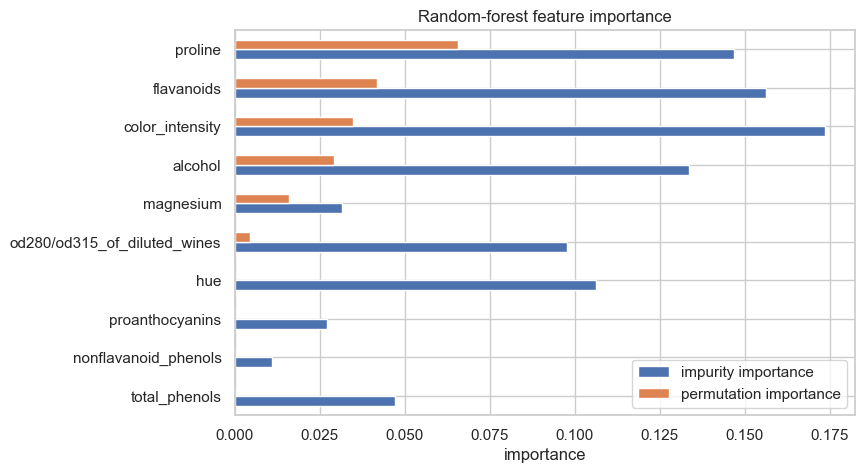

In [4]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

forest = RandomForestClassifier(n_estimators=400, max_features="sqrt", min_samples_leaf=2,
                                oob_score=True, n_jobs=1, random_state=42)
forest.fit(X_train, y_train)
perm = permutation_importance(forest, X_test, y_test, n_repeats=25, random_state=42, n_jobs=1)
importance = pd.DataFrame({"impurity importance": forest.feature_importances_, "permutation importance": perm.importances_mean}, index=X.columns).sort_values("permutation importance")
print(f"OOB accuracy: {forest.oob_score_:.3f}; test accuracy: {accuracy_score(y_test, forest.predict(X_test)):.3f}")
importance.tail(10).plot.barh(figsize=(8, 5), title="Random-forest feature importance")
plt.xlabel("importance"); plt.show()

## 4. Boosting and regularization

Boosting adds weak learners sequentially, fitting later learners to earlier errors. Gradient boosting minimizes a differentiable loss by following its negative gradient. Key hyperparameters are learning rate, number of estimators, tree depth, and subsampling. More trees are not always better: a small learning rate generally needs more trees, and validation/early stopping guards against overfitting.

| Method | Strength | Main risk |
|---|---|---|
| kNN | local, simple decision rule | scaling and slow prediction |
| single tree | interpretable rules | high variance |
| random forest | robust nonlinear baseline | less transparent, large model |
| gradient boosting | strong tabular accuracy | overfitting without tuning |

In [5]:
# A modest learning rate and shallow learners are deliberate regularization choices.
boost = GradientBoostingClassifier(n_estimators=180, learning_rate=.05, max_depth=2, subsample=.8, random_state=42)
boost.fit(X_train, y_train)
comparison = pd.Series({
    "tuned kNN": accuracy_score(y_test, search.predict(X_test)),
    "pruned tree": accuracy_score(y_test, tree.predict(X_test)),
    "random forest": accuracy_score(y_test, forest.predict(X_test)),
    "gradient boosting": accuracy_score(y_test, boost.predict(X_test)),
}).sort_values(ascending=False)
comparison.to_frame("test accuracy")

,test accuracy
random forest,1.000000
gradient boosting,0.977778
pruned tree,0.955556
tuned kNN,0.955556


## Summary and key takeaways

- Keep one untouched test set; tune hyperparameters with cross-validation on training data.
- Standardize numerical features for kNN and encode categoricals without inventing false order.
- Constrain trees before trusting their rules; a visually complex tree is often overfit.
- Random forests reduce tree variance; assess feature importance with care and validate it on held-out data.
- Boosting can be excellent for structured data but needs regularization and validation.

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 6. Concepts are informed by the supplied PDF; all explanations and code in this notebook are original.